# Analysis 3: Dealer vs. Individual Seller Dynamics
**Jira User Story:** `CDS-76` — Advanced Analysis (Acceptance Criterion 3)  
**Business Question:** Do Dealers and Individuals list vehicles at different prices, and how do their inventory age, mileage, and specification profiles differ? (`Trustmark Dealer`, `n = 173`, is analyzed separately.)

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

SCRIPTS_DIR = Path("scripts").resolve()
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from common import load_dataset, OUTPUT_FIG_DIR
from seller_dynamics_analysis import run_seller_dynamics_analysis

df = load_dataset()
res3 = run_seller_dynamics_analysis(df)
summary_df = pd.DataFrame(res3["seller_summary"])
display(summary_df.style.format({
    "share_pct": "{:.2f}%",
    "mean_price": "₹{:,.0f}",
    "median_price": "₹{:,.0f}",
    "std_price": "₹{:,.0f}",
    "p25_price": "₹{:,.0f}",
    "p75_price": "₹{:,.0f}",
    "mean_age": "{:.2f}",
    "mean_km": "{:,.0f}",
    "median_km": "{:,.0f}",
    "automatic_share_pct": "{:.2f}%",
}))
print("\nRaw Relative Listing-Price Difference (Dealer vs Individual):", res3["dealer_vs_individual_raw"])

,seller_type,analysis_role,count,share_pct,mean_price,median_price,std_price,p25_price,p75_price,median_age,mean_age,p25_age,p75_age,median_km,mean_km,p25_km,p75_km,automatic_share_pct,median_engine_cc,median_power_bhp
0,Dealer,Primary Comparison,9446,62.03%,"₹870,206","₹590,000","₹1,023,733","₹411,000","₹890,000",6.000000,6.15,4.000000,8.000000,"50,000","52,478",32000.000000,68000.000000,27.05%,1396.000000,88.760000
1,Individual,Primary Comparison,5610,36.84%,"₹619,702","₹510,000","₹606,082","₹350,000","₹730,000",5.000000,5.92,3.000000,8.000000,"50,000","59,672",25742.000000,80000.000000,10.09%,1248.000000,82.000000
2,Trustmark Dealer,Separate (Small Sample),173,1.14%,"₹571,960","₹540,000","₹226,203","₹410,000","₹675,000",4.000000,4.29,3.000000,5.000000,"28,810","31,339",14971.000000,45280.000000,14.45%,1197.000000,81.830000



Raw Relative Listing-Price Difference (Dealer vs Individual): {'dealer_median_inr': 590000.0, 'individual_median_inr': 510000.0, 'absolute_median_diff_inr': 80000.0, 'relative_listing_price_diff_pct': 15.686274509803933}


### Raw Price & Inventory Profile Findings
- **Relative Median Listing-Price Difference:** Dealers (`n = 9,446`, median **`₹5.90L`**, mean `₹8.70L`) list **`+15.69%`** (`+₹80,000`) higher than Individuals (`n = 5,610`, median **`₹5.10L`**, mean `₹6.20L`). *(Note: This is a relative listing-price difference, not dealer profit or acquisition markup.)*
- **Why Raw Prices Differ (Inventory Mix):** Dealers actually hold slightly older inventory (`median 6.0y / mean 6.15y` vs. Individual `5.0y / 5.92y`) with identical median mileage (`50,000 km`, mean `52,478` vs. `59,672 km`), **but carry 2.7× more Automatic vehicles (`27.05%` vs. `10.09%`), larger engines (`median 1,396 cc` vs. `1,248 cc`), and the luxury upper tail**.
- **Trustmark Dealer (Separate, `n = 173`):** Specializes in newer, lower-mileage certified mass-market cars (`median age 4.0y`, `median 28,810 km`, `median 1,197 cc`, median price `₹5.40L`).

=== Full Dataset (n=15,229) | R²=0.9220, Adj R²=0.9215 ===


,coef,hc3_se,t_stat,p_value,ci95_low,ci95_high,pct_diff_vs_individual,pct_ci95_low,pct_ci95_high
Dealer,0.055041,0.003614,15.231242,2.193833e-52,0.047959,0.062124,5.658421,4.912714,6.409429
Trustmark Dealer,-0.028034,0.011487,-2.440541,1.466527e-02,-0.050548,-0.005520,-2.764476,-4.929155,-0.550510


=== Major Body Types Sensitivity (n=9,817) | R²=0.9183, Adj R²=0.9177 ===


,coef,hc3_se,t_stat,p_value,ci95_low,ci95_high,pct_diff_vs_individual,pct_ci95_low,pct_ci95_high
Dealer,0.052779,0.004705,11.217263,3.354935e-29,0.043557,0.062001,5.419674,4.451967,6.396346
Trustmark Dealer,-0.002181,0.019492,-0.111913,9.108920e-01,-0.040386,0.036023,-0.217909,-3.958136,3.667976


--- seller_price_comparison.png ---


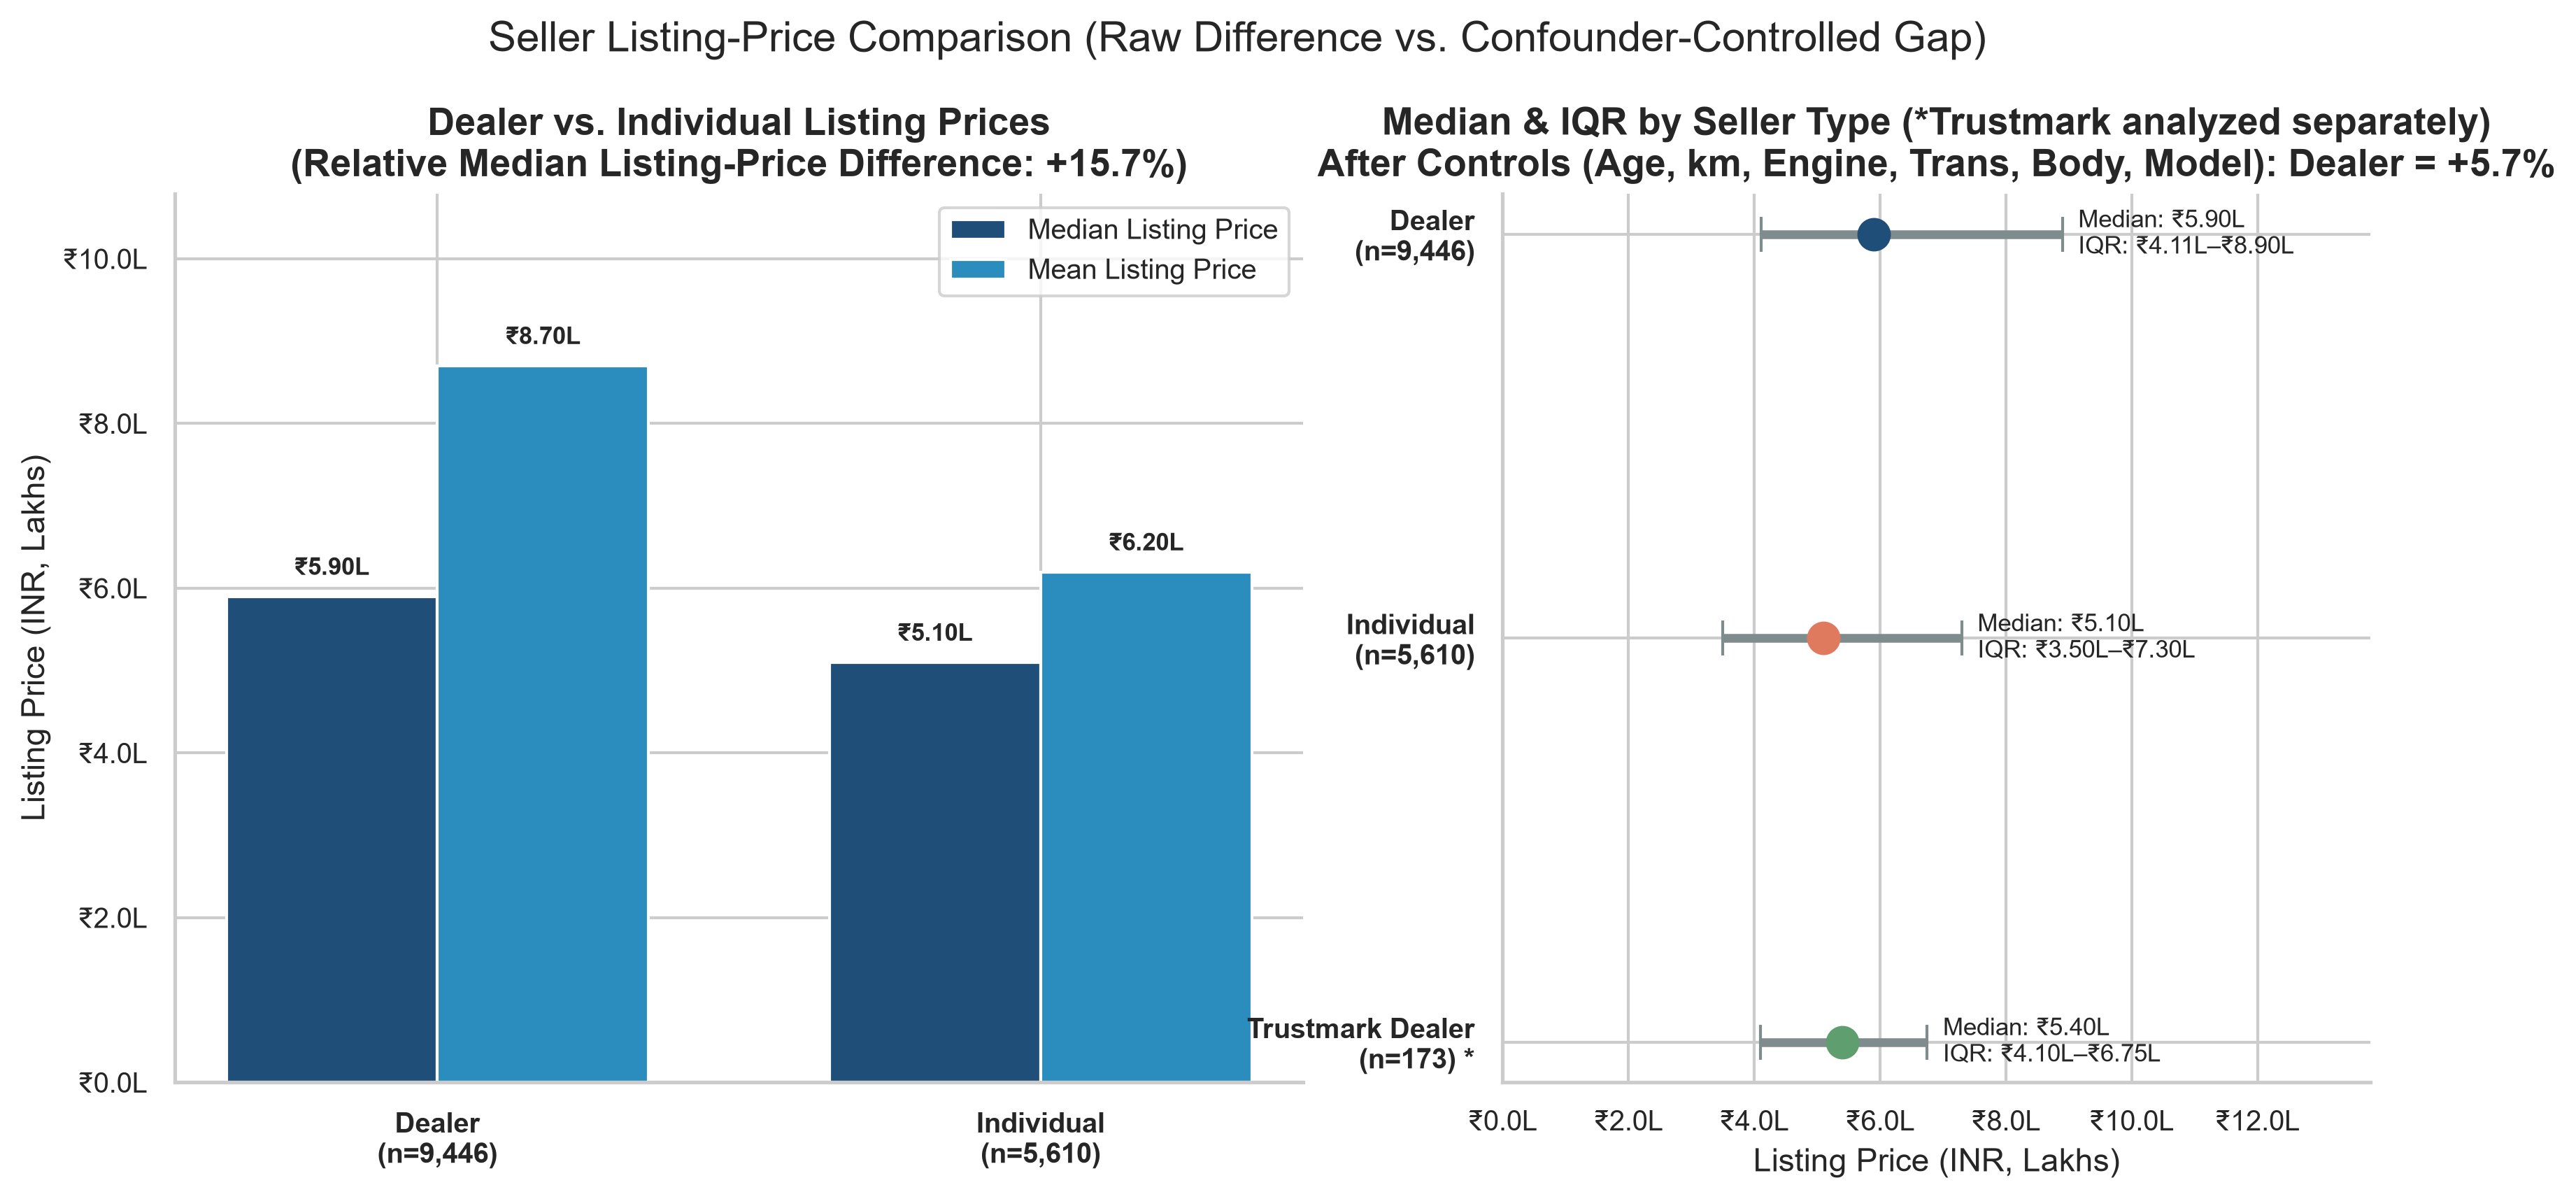

--- seller_vehicle_age_comparison.png ---


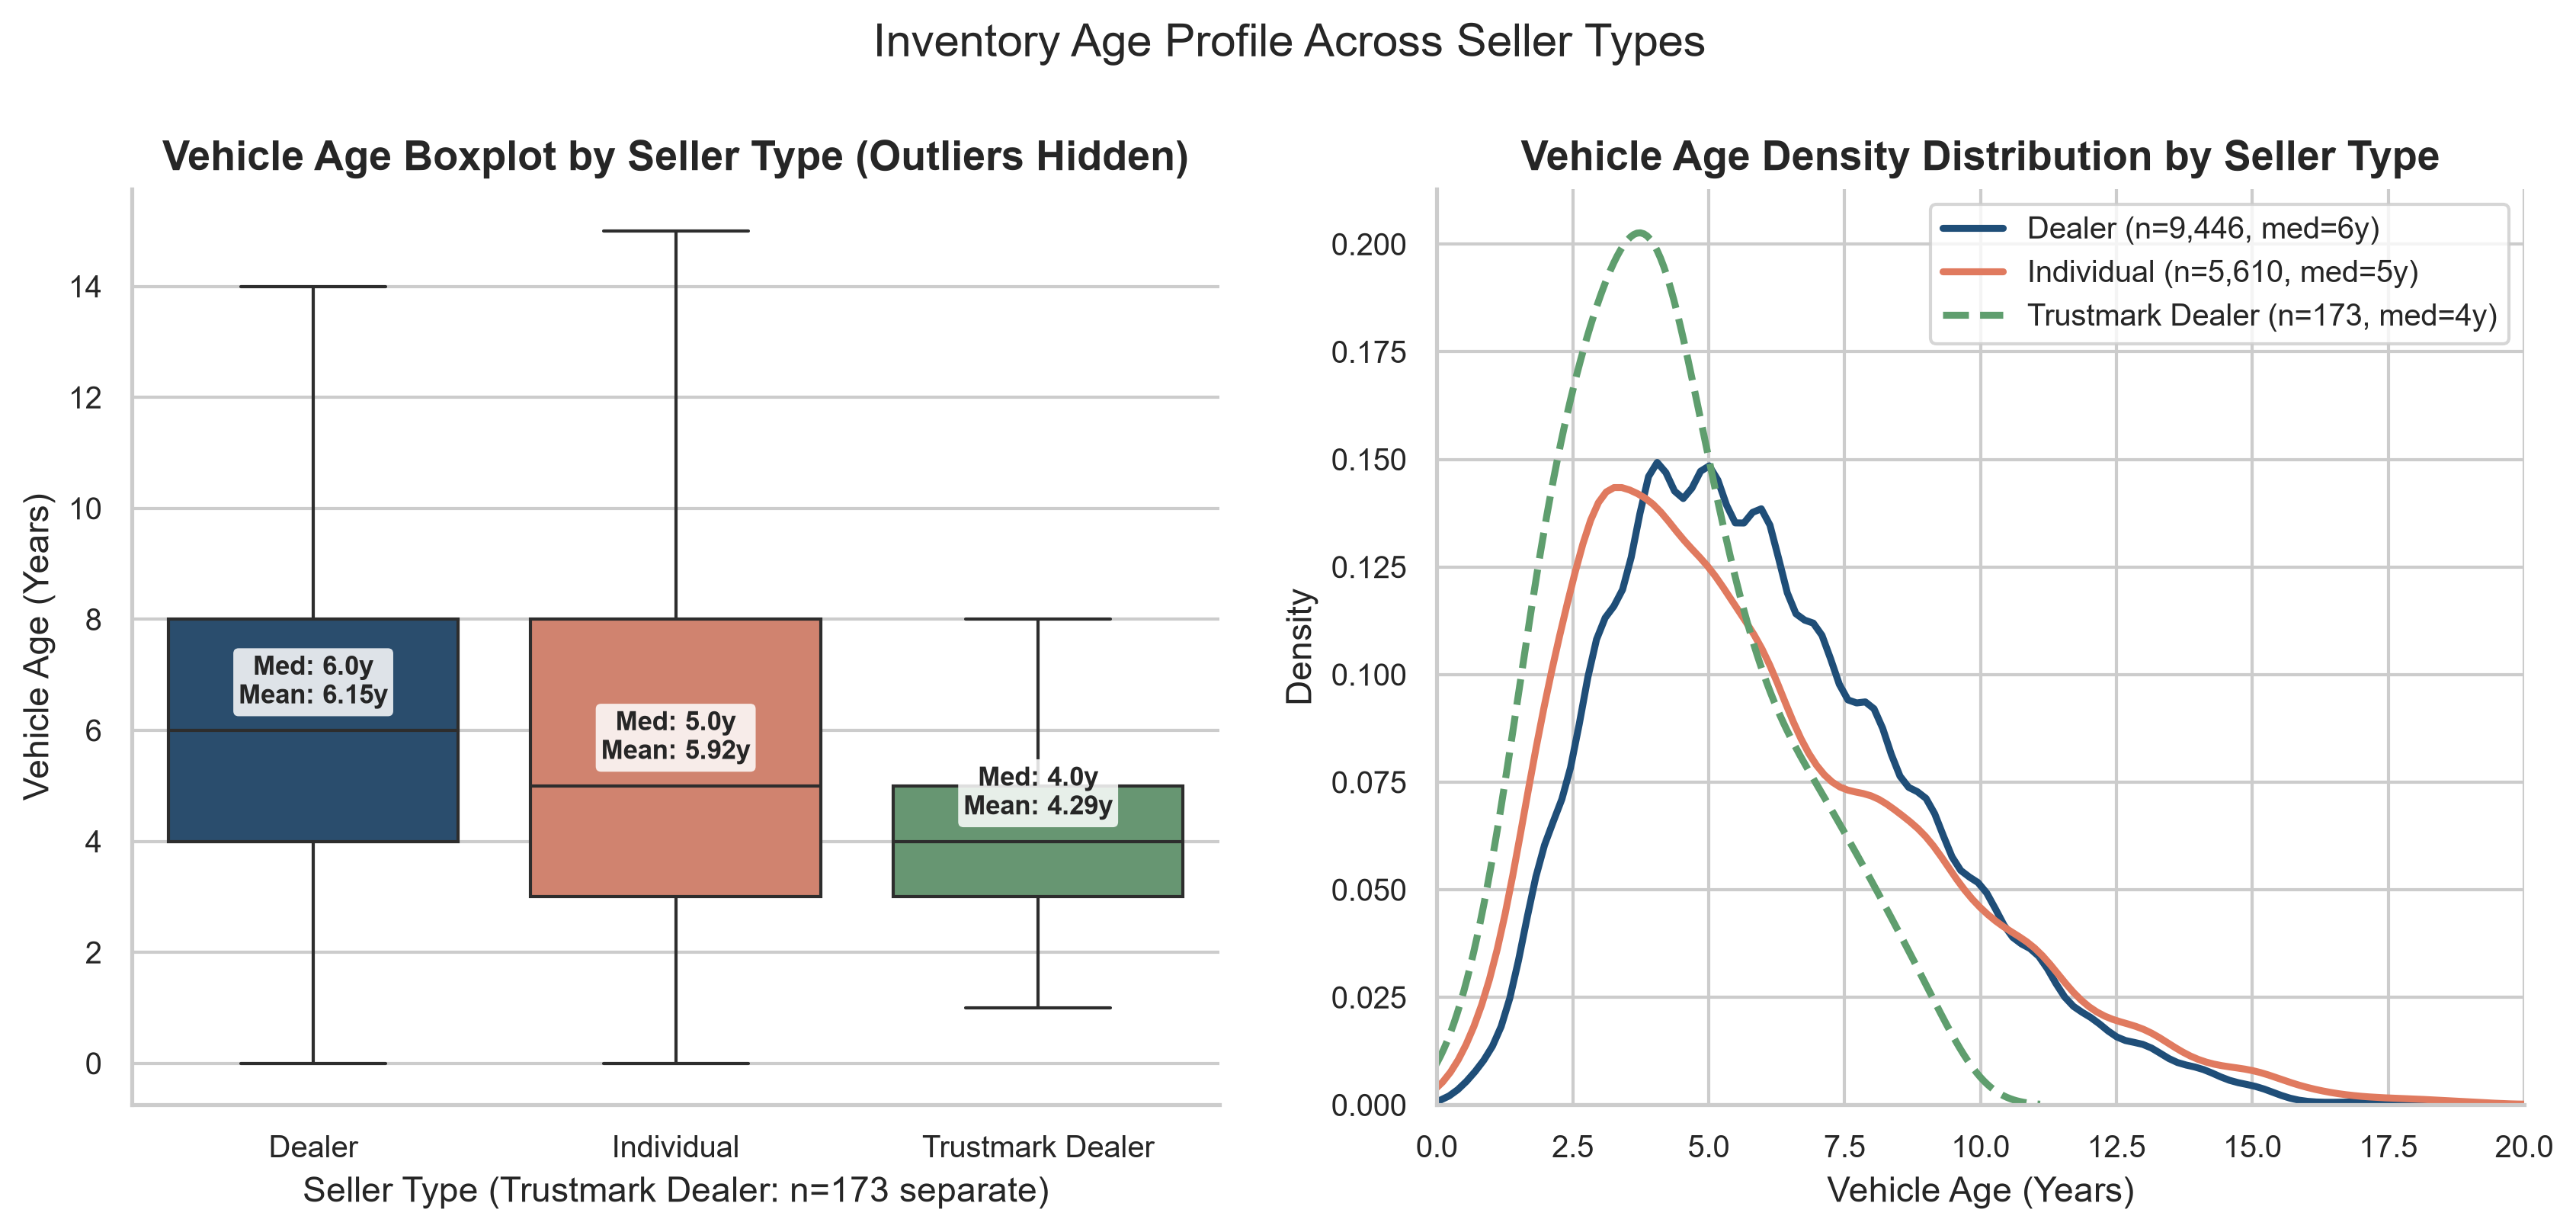

--- seller_mileage_comparison.png ---


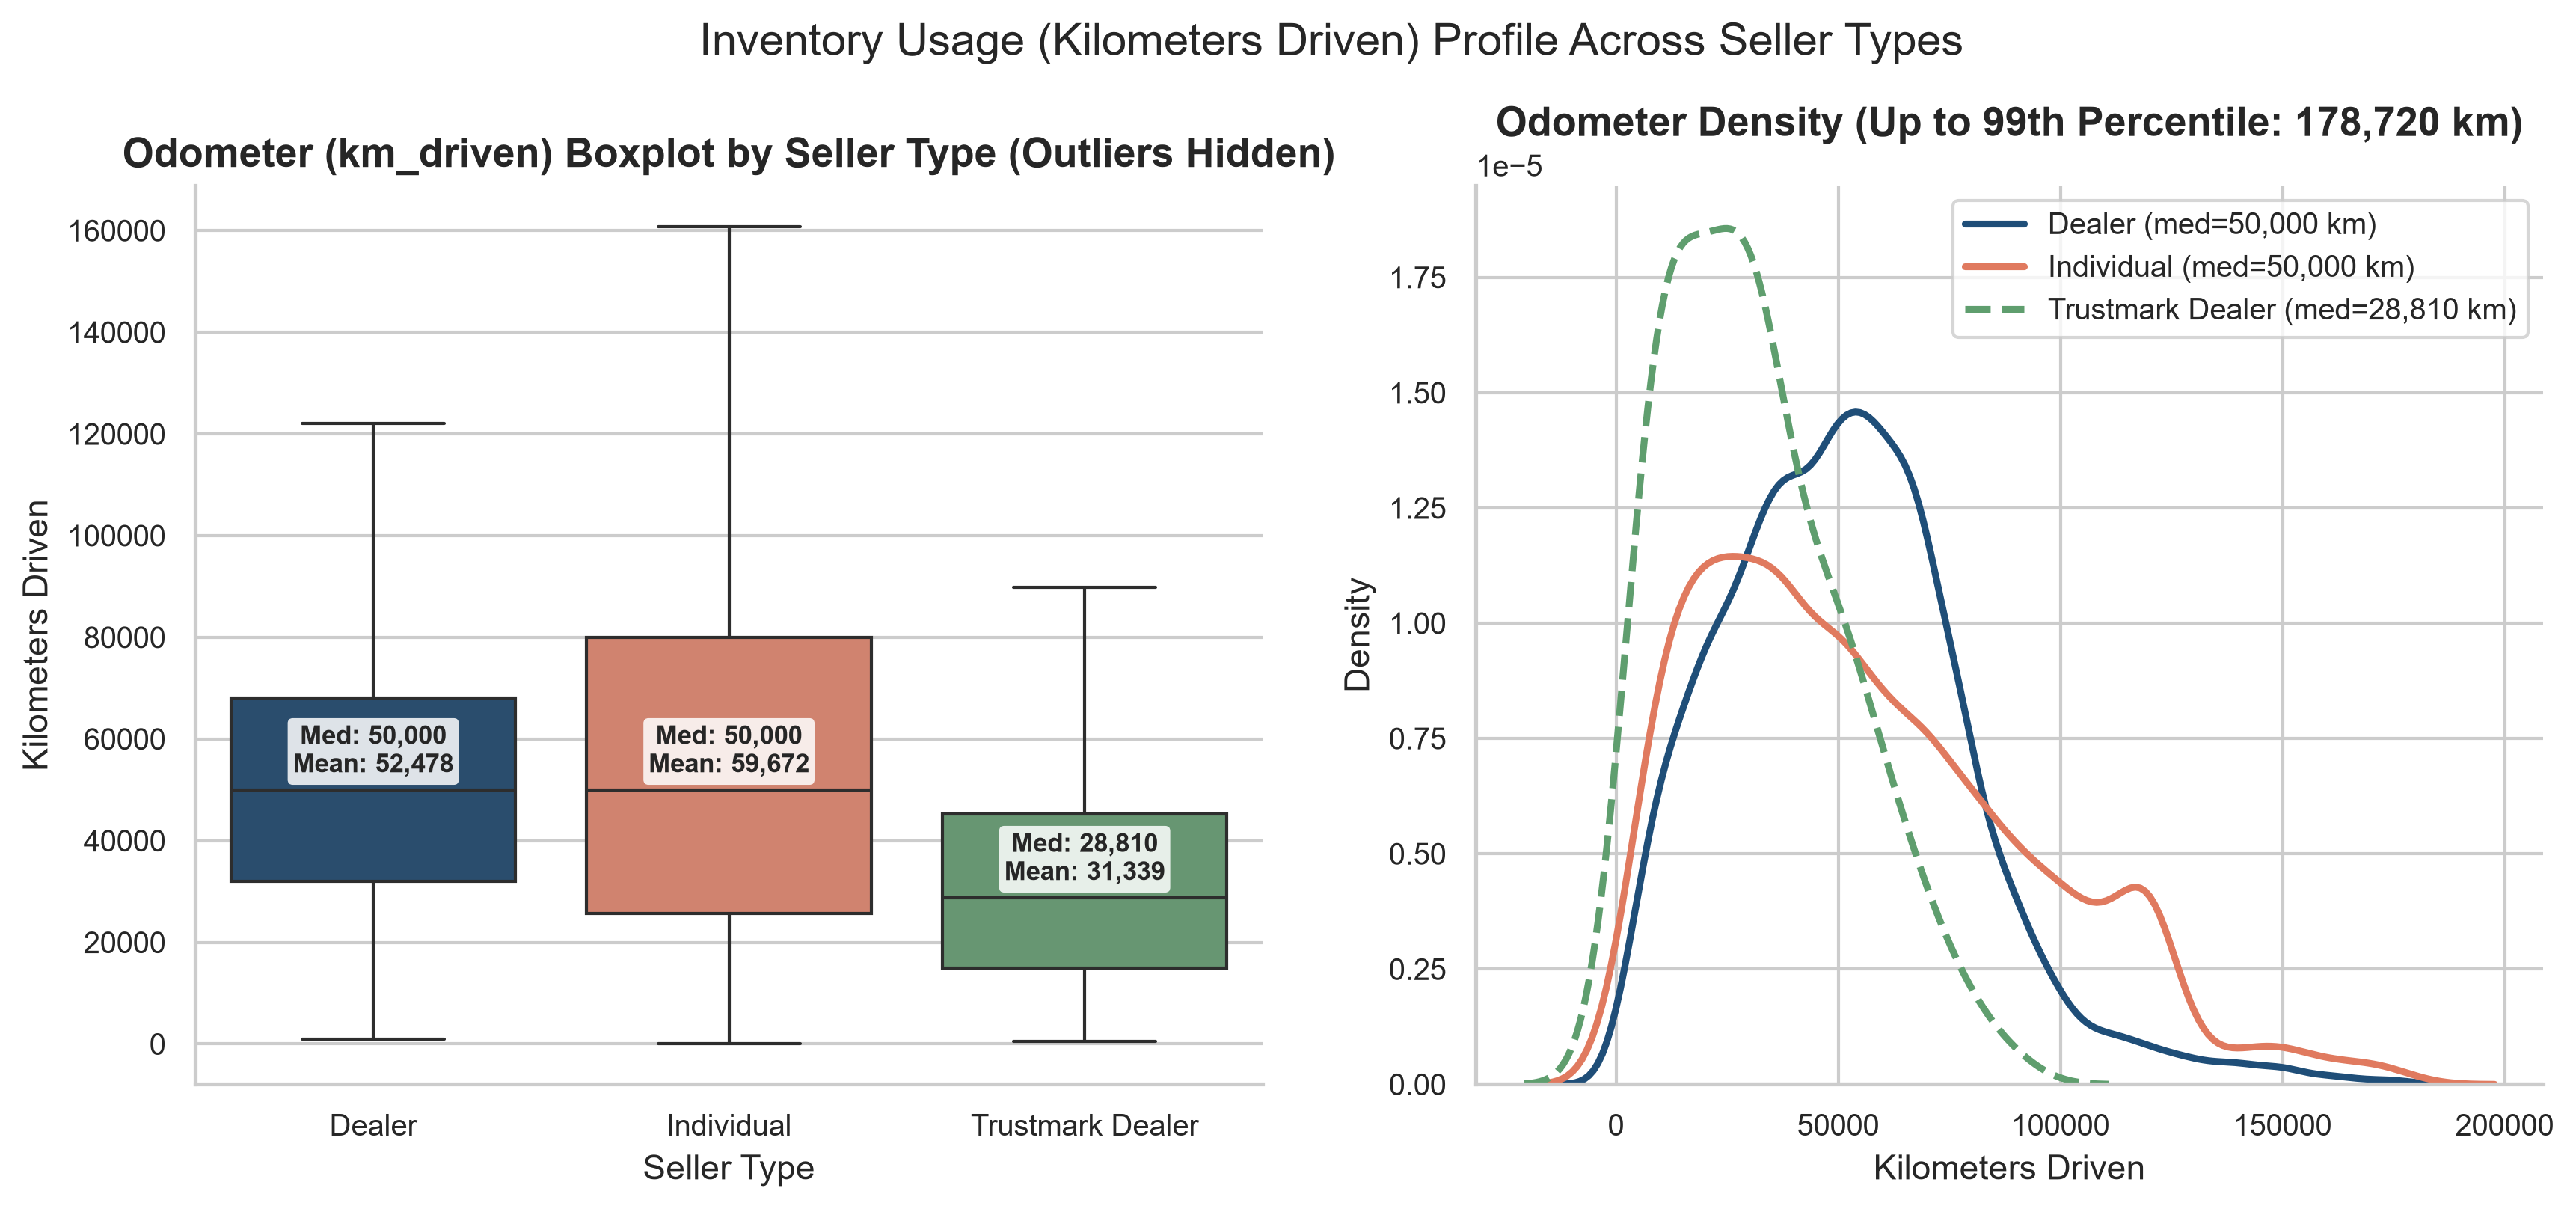

--- seller_price_distribution.png ---


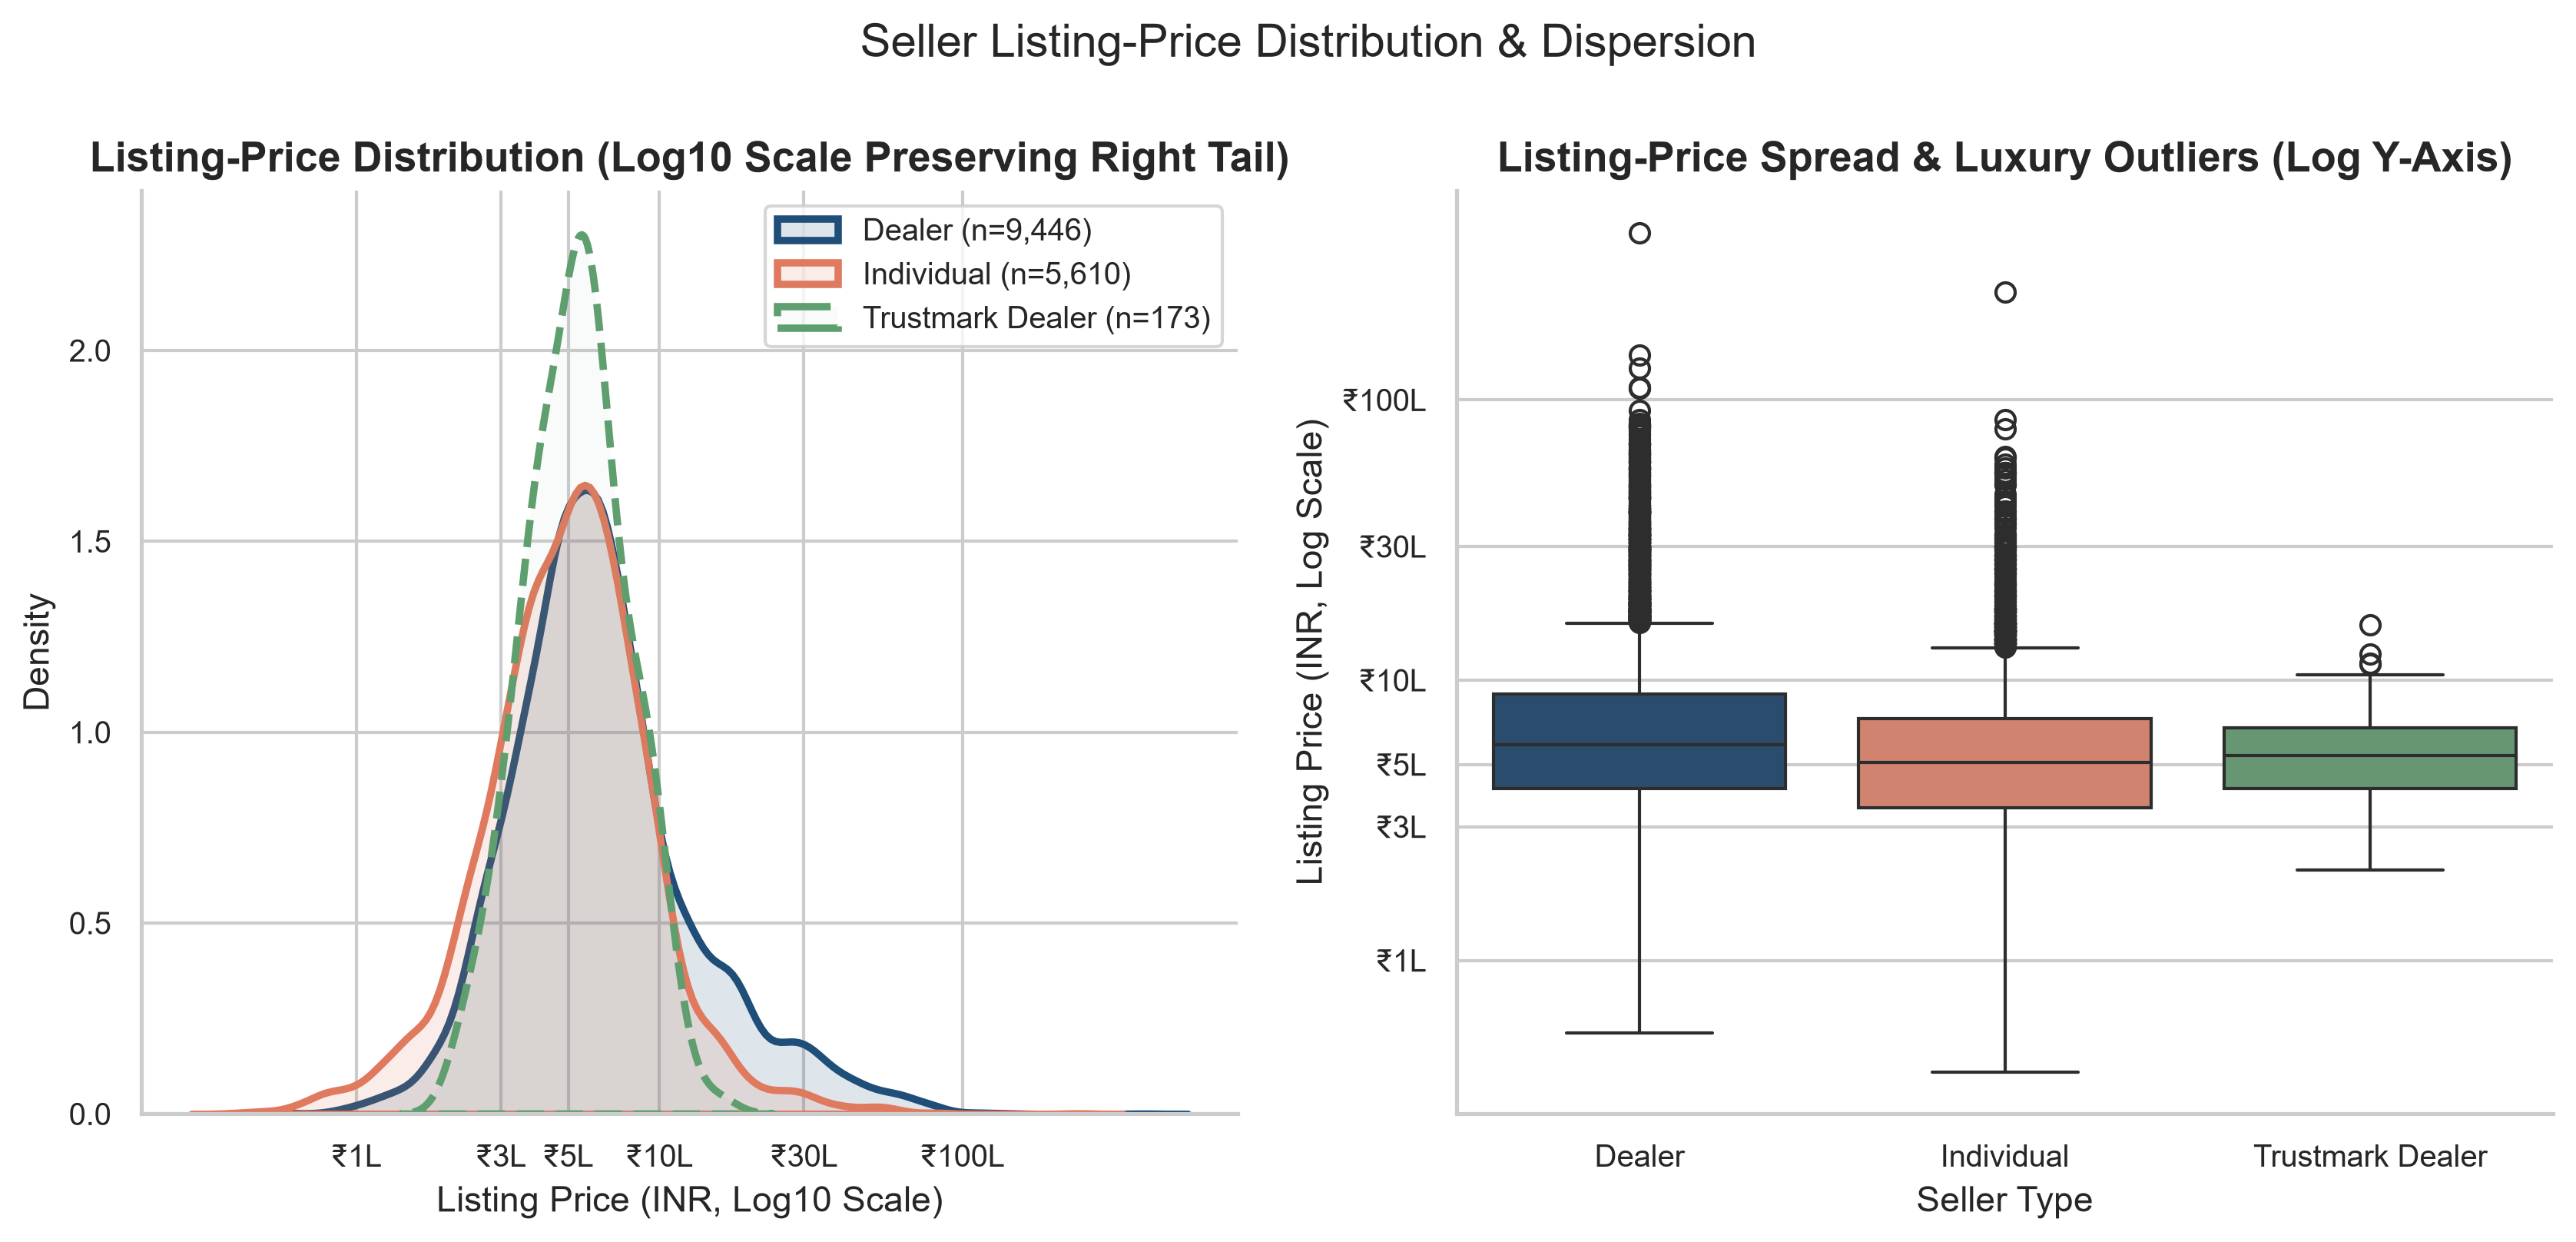

In [2]:
for label, reg in [("Full Dataset (n=15,229)", res3["regression_full"]), ("Major Body Types Sensitivity (n=9,817)", res3["regression_major_body_sensitivity"])]:
    print(f"=== {label} | R²={reg['r2']:.4f}, Adj R²={reg['adj_r2']:.4f} ===")
    display(pd.DataFrame(reg["seller_coefficients_vs_individual"]).T)

for fname in ["seller_price_comparison.png", "seller_vehicle_age_comparison.png", "seller_mileage_comparison.png", "seller_price_distribution.png"]:
    print(f"--- {fname} ---")
    display(Image(filename=str(OUTPUT_FIG_DIR / fname), width=780))

### Controlled Regression & Business Conclusion
- **Controlled Seller Gap (`R² = 0.9220`, HC3 robust SEs):** After accounting for `vehicle_age`, `km_driven`, `engine`, `transmission_type`, `real_body_type`, and `model_grouped`, **Dealers still list `+5.66%` higher than Individual sellers** (95% CI: `4.91%–6.41%`, `t = 15.23, p = 2.19e-52`), confirmed on the major-body subset (`+5.42%`, `p = 3.35e-29`).
- **Interpretation:** Roughly two-thirds of the raw `+15.69%` Dealer price advantage comes from stocking higher-spec/automatic/luxury inventory; the remaining **`~5.7%`** reflects a persistent dealer listing premium (consistent with warranty, inspection, showroom overhead, and negotiation headroom). Trustmark Dealers price essentially at parity with Individuals (`-2.76%`, `p = 0.015` overall; `-0.22%`, `p = 0.911` on major body types) once vehicle age and low mileage are controlled.